# Virtual Cell Sandbox
**Shichuan Cheng · CISC7204 Practice 09**

Research question: can simple models predict a simulated gene-inhibition response, and do they generalize to an unseen dose?

**All data and interactions are synthetic.** This is an educational prototype, not a validated biological model. See the repository README for the equations, assumptions, permissions and limitations.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/virtual_cell.py").exists(), "Run from the project root or notebooks folder"
sys.path.insert(0, str(ROOT / "src"))
from analyze import main
from virtual_cell import GENES
main()

    evaluation         model      MAE        R2
Held-out cells   No response 0.608993 -1.031149
Held-out cells         Ridge 0.145308  0.903859
Held-out cells Random forest 0.051343  0.987893
New dose (60%)   No response 0.804392 -7.158009
New dose (60%)         Ridge 0.129802  0.715822
New dose (60%) Random forest 0.230171  0.338978
Saved 3600 rows, metrics, split manifest and six figures in the project directory.


## 1. Inspect the generated dataset
400 paired cell identities, nine conditions and four genes. The six baseline/dose inputs contain no endpoint measurements. Repeated cells must be grouped when splitting.

In [2]:
cells = pd.read_csv(ROOT / "data/synthetic_cells.csv")
print("Rows:", len(cells), "| Cells:", cells.cell_id.nunique())
print("Missing values:", cells.isna().sum().sum())
display(cells.head())
display(cells.groupby(["domain", "condition"]).size().rename("rows").to_frame())

Rows: 3600 | Cells: 400
Missing values: 0


,cell_id,condition,dose_A,dose_B,domain,baseline_TF_A,post_TF_A,lfc_TF_A,baseline_TF_B,post_TF_B,lfc_TF_B,baseline_Growth,post_Growth,lfc_Growth,baseline_Stress,post_Stress,lfc_Stress
0,0,Control,0.0,0.0,standard,1.839428,1.777735,-0.049217,2.527949,2.680303,0.084428,2.398036,2.517263,0.070003,0.502820,0.440997,-0.189275
1,1,Control,0.0,0.0,standard,1.611310,1.543379,-0.062142,1.703667,1.689677,-0.011896,2.635527,2.620873,-0.008044,0.851099,0.876495,0.042419
2,2,Control,0.0,0.0,standard,1.703485,1.699047,-0.003763,1.851985,1.882275,0.023405,1.985669,2.024663,0.028057,0.468668,0.440358,-0.089890
3,3,Control,0.0,0.0,standard,1.569783,1.639714,0.062879,1.513102,1.533089,0.018932,1.939173,2.000006,0.044563,0.490954,0.492226,0.003733
4,4,Control,0.0,0.0,standard,1.500587,1.471563,-0.028178,1.037105,1.080164,0.058689,1.193532,1.220852,0.032651,0.891897,0.903975,0.019406


rows
domain     condition      
novel_dose A_0.6       400
           B_0.6       400
standard   A_0.25      400
           A_0.5       400
           A_0.75      400
           B_0.25      400
           B_0.5       400
           B_0.75      400
           Control     400

## 2. Inspect the evaluation split
Familiar-dose and novel-dose evaluation both use held-out cell identities. The 60% dose is excluded from training entirely.

In [3]:
import json
split = json.loads((ROOT / "results/split.json").read_text())
assert set(split["train_cell_ids"]).isdisjoint(split["test_cell_ids"])
print({k:v for k,v in split.items() if not k.endswith("ids")})
print("Train cells:", len(split["train_cell_ids"]), "| Test cells:", len(split["test_cell_ids"]))

{'seed': 7204, 'training_rows': 2100, 'held_out_rows': 700, 'new_dose_rows': 200}
Train cells: 300 | Test cells: 100


## 3. Interpret the intervention response
In the assumed network, B activates Growth and represses Stress. Decreasing B therefore lowers Growth and increases Stress. This is a check of the simulator's behavior, not evidence for a real gene interaction.

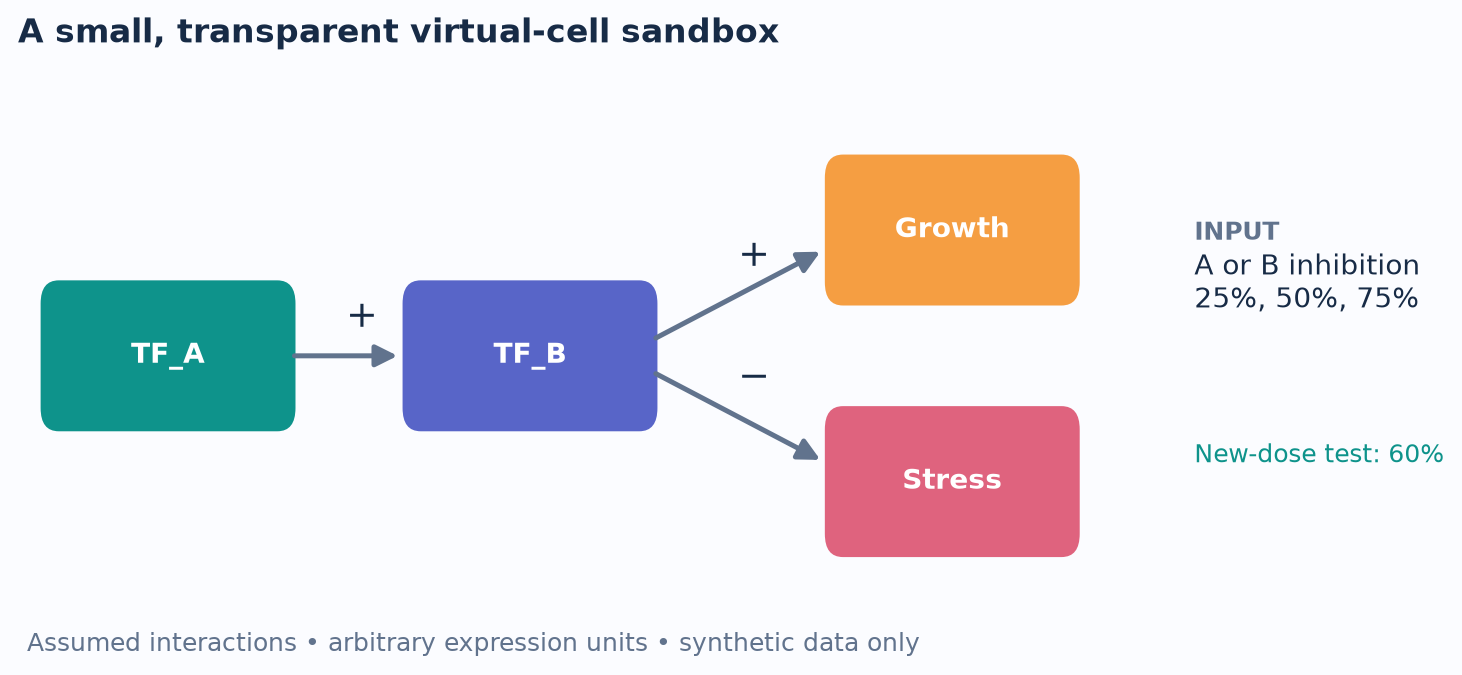

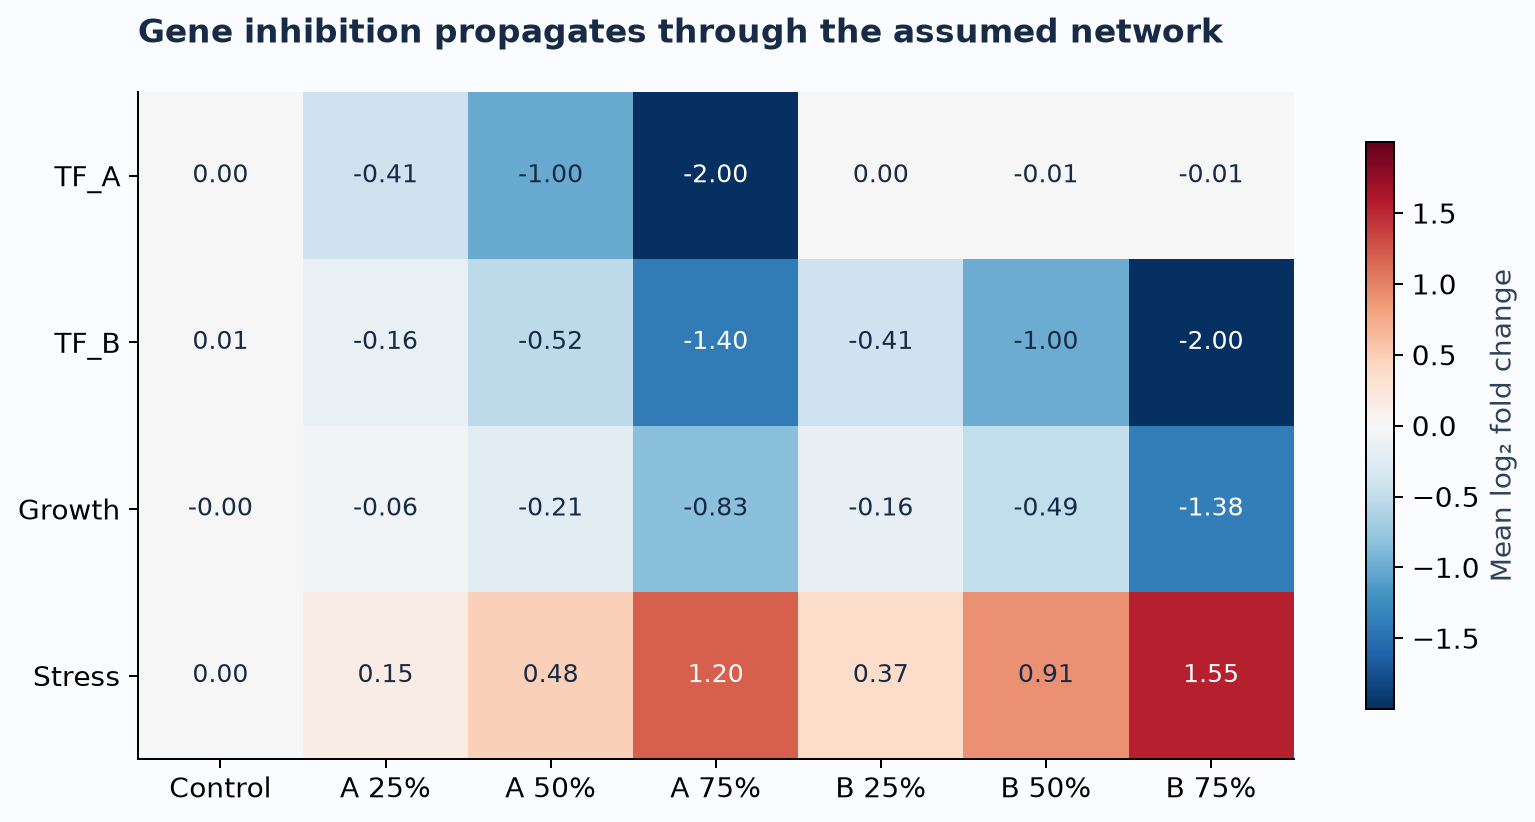

In [4]:
display(Image(filename=str(ROOT / "figures/01_network.png")))
display(Image(filename=str(ROOT / "figures/02_response_heatmap.png")))

## 4. Compare predictive models
MAE is averaged across four log2-fold-change targets. The random forest wins at familiar doses, but Ridge wins at the unseen 60% dose. This reversal shows why an evaluation should test the intended use case.

,evaluation,model,MAE,R2
0,Held-out cells,No response,0.6090,-1.0311
1,Held-out cells,Ridge,0.1453,0.9039
2,Held-out cells,Random forest,0.0513,0.9879
3,New dose (60%),No response,0.8044,-7.1580
4,New dose (60%),Ridge,0.1298,0.7158
5,New dose (60%),Random forest,0.2302,0.3390


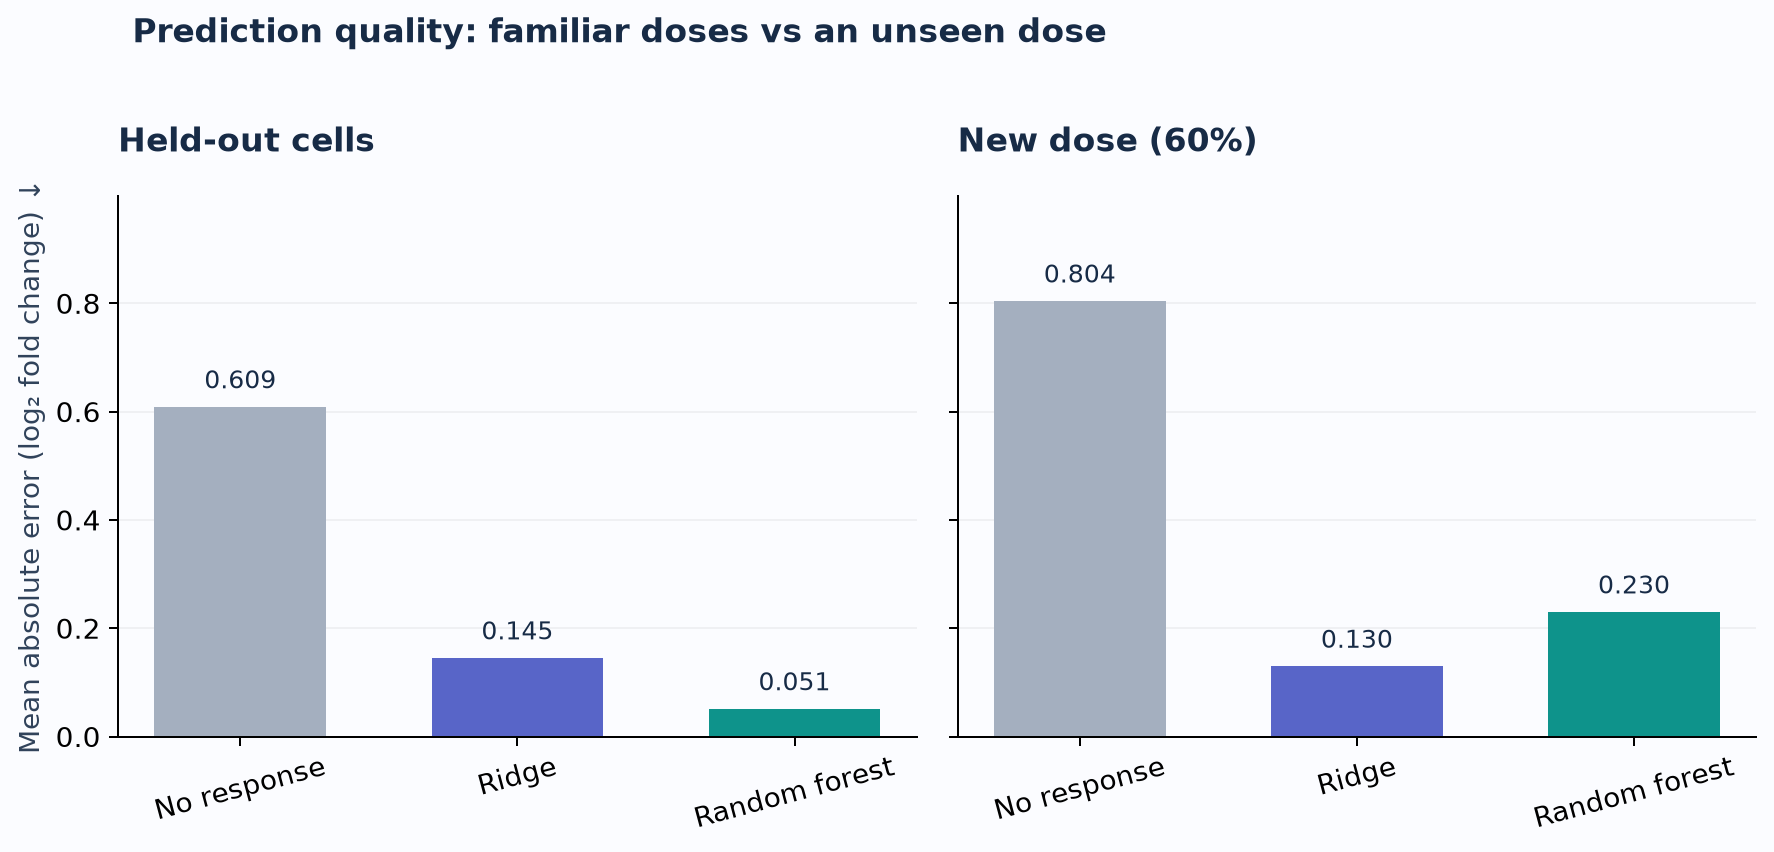

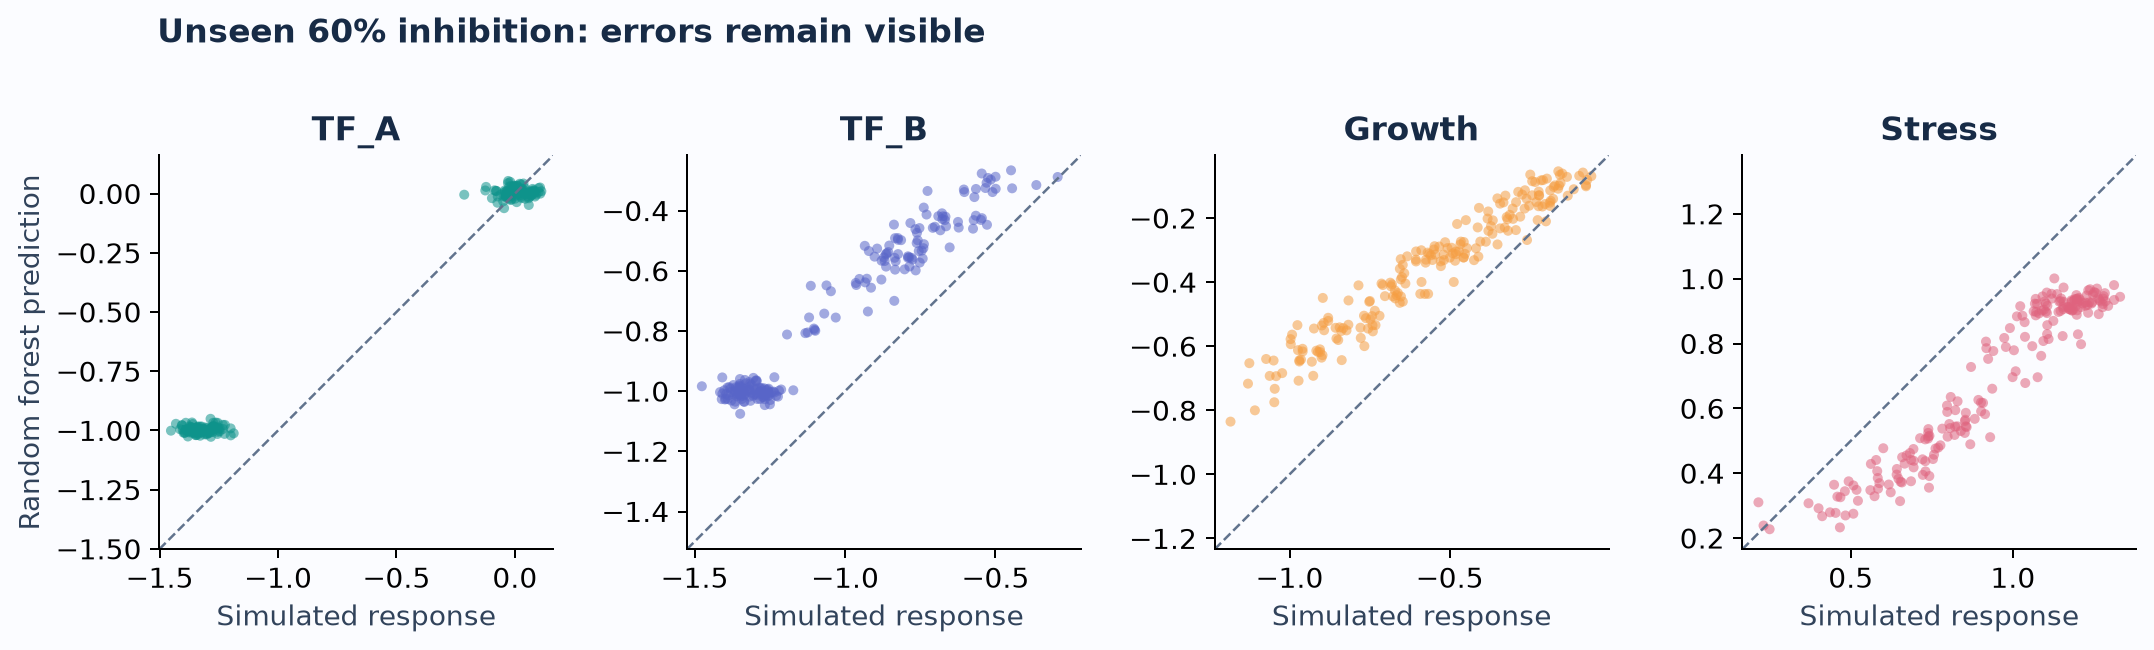

In [5]:
metrics = pd.read_csv(ROOT / "results/metrics.csv")
display(metrics.round(4))
display(Image(filename=str(ROOT / "figures/03_model_comparison.png")))
display(Image(filename=str(ROOT / "figures/04_prediction_scatter.png")))

## 5. Inspect dose response and model interpretation
Error bars are ±1.96 SE across synthetic cells. Feature importance describes the fitted forest and should not be interpreted as causal evidence.

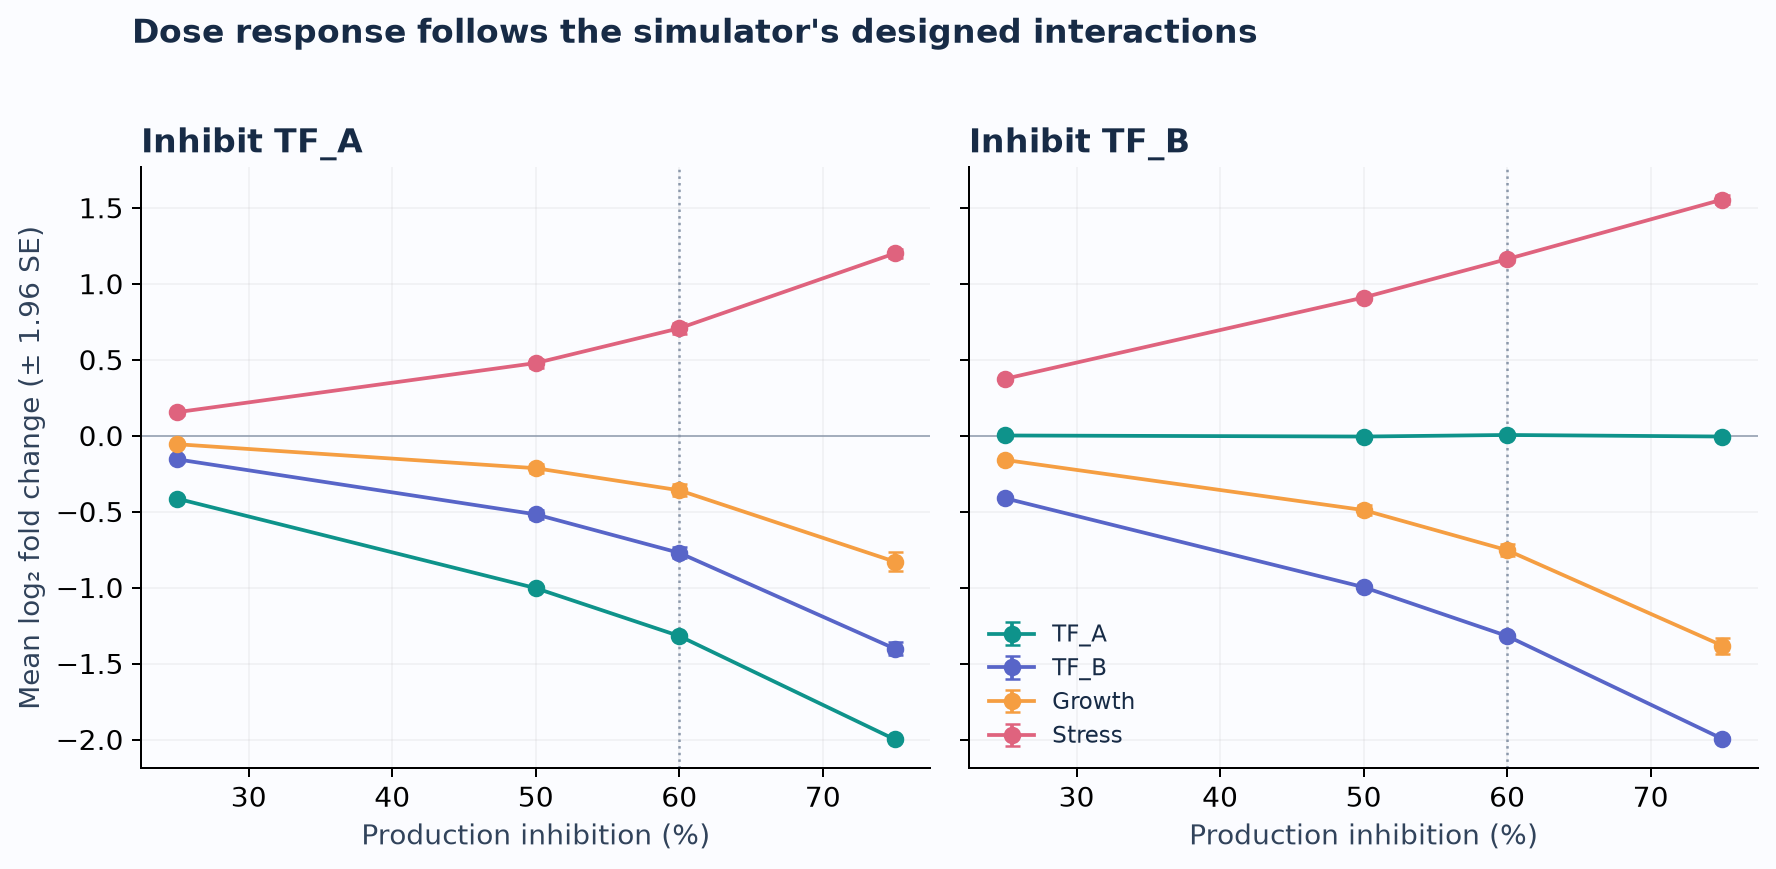

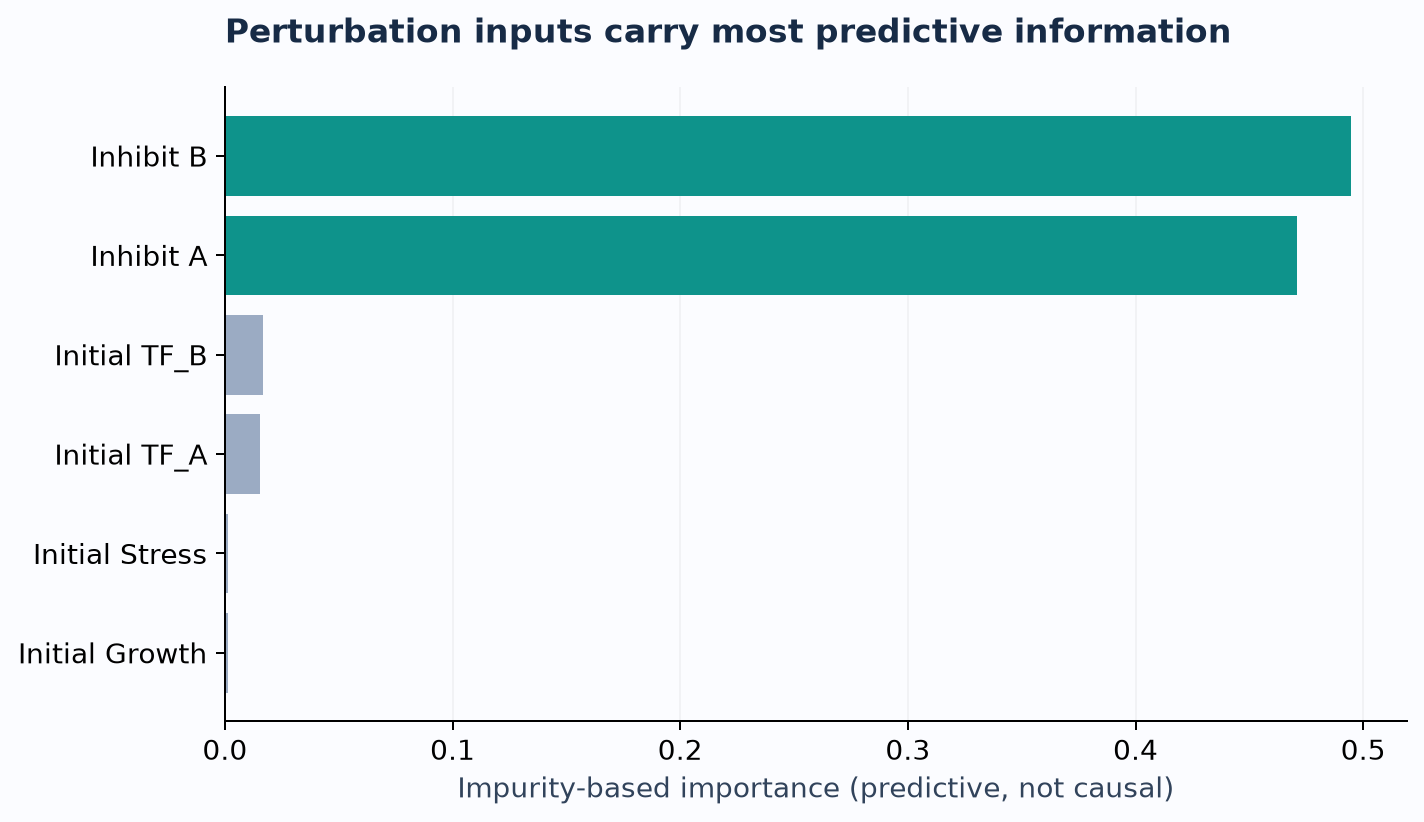

In [6]:
display(Image(filename=str(ROOT / "figures/05_dose_response.png")))
display(Image(filename=str(ROOT / "figures/06_feature_importance.png")))

## 6. Limitations and next experiment
All observations come from one assumed four-gene simulator. The result cannot establish generalization to real cells, unseen cell types or biological replicates. There is one train/test split and no model-ranking confidence interval.

Next: repeat grouped evaluation across several seeds, then evaluate on a licensed real perturbation dataset. Use an independent validation split before tuning. The classmate review requested by the course is pending; no feedback has been invented.

**AI assistance:** OpenAI Codex helped design, implement, document and debug this project. All numerical findings above were produced by executing the included code.